### 04c. Analysis by Label, TF-IDF and Visualizations

#### Read-In Data and Load Packages

In [1]:
import numpy as np
import pandas as pd               
import plotnine
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
import re


In [12]:
df_rules = pd.read_csv("../data/fr_rules_labels_metadata.csv")

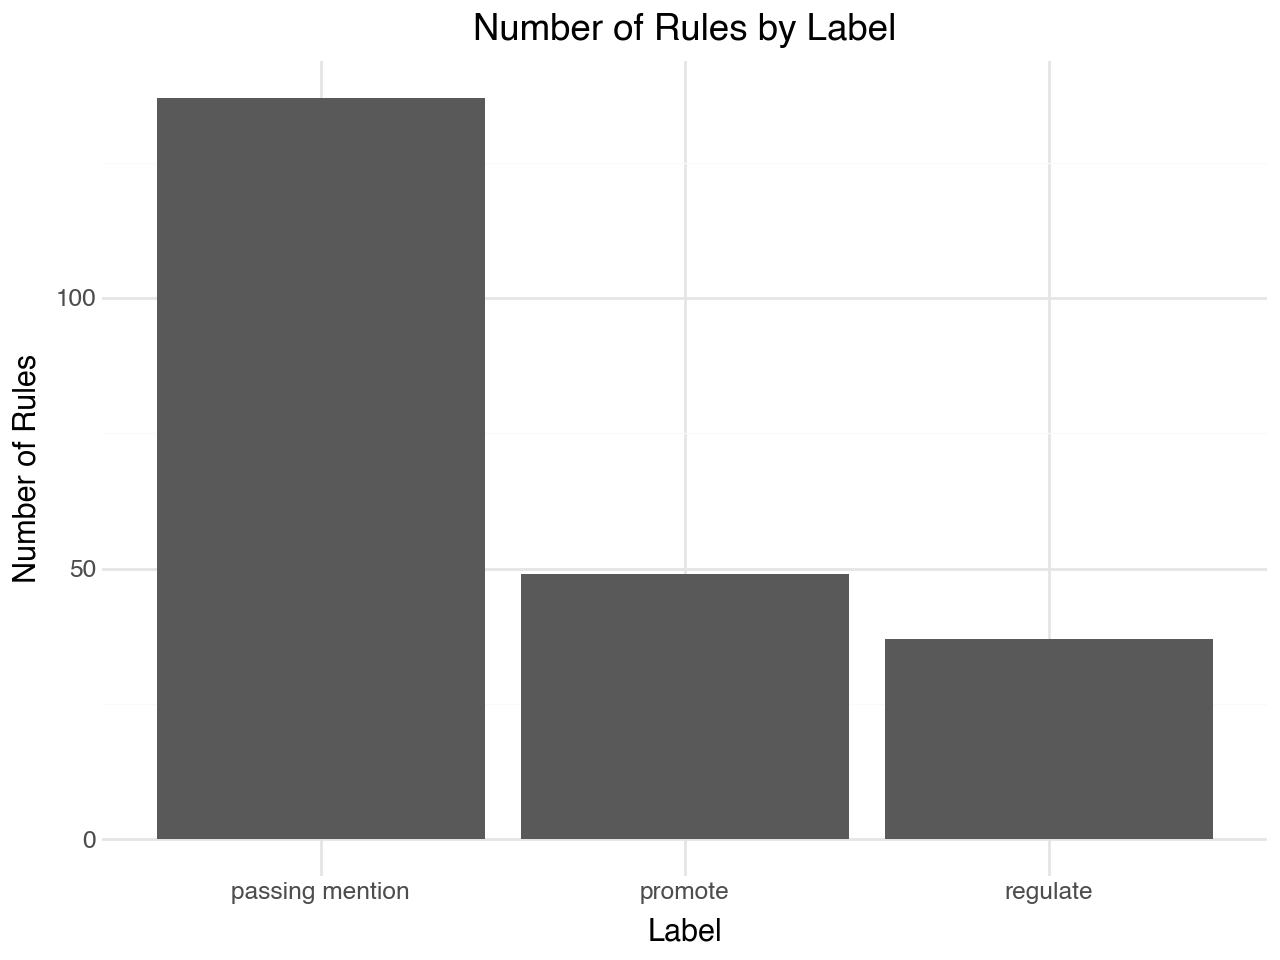

In [13]:
plot1 = (plotnine.ggplot(df_rules, plotnine.aes(x='gemini_label'))
               + plotnine.geom_bar(position='dodge')
               + plotnine.labs(title='Number of Rules by Label',
                        x='Label',
                        y='Number of Rules')
                + plotnine.theme(axis_text_x=plotnine.element_text(rotation=45, hjust=1))
                + plotnine.theme_minimal())

plot1

### TF-IDF BY Label

In [14]:
#functions from HW4
def clean_post(text):
    """Lowercase the text, remove most punctuation, and tidy up spaces."""
    lowered = str(text).lower()
    # Replace anything that isn't a-z, 0-9, a space, an apostrophe, or a hyphen with a space.
    no_punctuation = re.sub(r"[^a-z0-9\s'-]", " ", lowered)
    # Turn runs of spaces into a single space, and trim both ends.
    return re.sub(r"\s+", " ", no_punctuation).strip()

def compare_groups(vectorizer, matrix, mask_a, mask_b, n=15):
    """Return the words whose average score differs most between two groups of rows."""
    average_a = np.asarray(matrix[mask_a].mean(axis=0)).ravel()
    average_b = np.asarray(matrix[mask_b].mean(axis=0)).ravel()
    difference = pd.DataFrame({
        "term": vectorizer.get_feature_names_out(),
        "difference": average_a - average_b,
    }).sort_values("difference", ascending=False)
    return pd.DataFrame({
        "leans_a": difference["term"].head(n).to_numpy(),
        "leans_b": difference["term"].tail(n)[::-1].to_numpy(),
    })

custom_stop_words = list(ENGLISH_STOP_WORDS | {"2019", "2020", "2021", "2022", "2023", "2024", "2025", "2026", "al", "et"})
project_vectorizer = TfidfVectorizer(stop_words=custom_stop_words, min_df=5)
df_rules["clean_text"] = df_rules["passages"].apply(clean_post)
project_matrix = project_vectorizer.fit_transform(df_rules["clean_text"])

In [15]:
regulate = (df_rules["gemini_label"] == "regulate").to_numpy()
allother_regulate = (df_rules["gemini_label"] != "regulate").to_numpy()
label_terms_regulate = compare_groups(project_vectorizer, project_matrix, regulate, allother_regulate, n=15)
label_terms_regulate.head(15)

,leans_a,leans_b
0,advanced,commenters
1,controls,data
2,items,commenter
3,military,code
4,computing,cms
5,ics,proposed
6,weapons,cpt
7,bis,comments
8,device,available
9,china,time


In [16]:
promote = (df_rules["gemini_label"] == "promote").to_numpy()
allother_promote = (df_rules["gemini_label"] != "promote").to_numpy()
label_terms_promote = compare_groups(project_vectorizer, project_matrix, promote, allother_promote, n=15)
label_terms_promote.head(15)

,leans_a,leans_b
0,comments,software
1,critical,stated
2,language,commenters
3,program,energy
4,hhs,device
5,individuals,commenter
6,support,use
7,experts,controls
8,priority,consumer
9,moving,information


In [17]:
passing_mention = (df_rules["gemini_label"] == "passing mention").to_numpy()
allother_passing_mention = (df_rules["gemini_label"] != "passing mention").to_numpy()
label_terms_passing_mention = compare_groups(project_vectorizer, project_matrix, passing_mention, allother_passing_mention, n=15)
label_terms_passing_mention.head(15)

,leans_a,leans_b
0,commenters,advanced
1,commenter,items
2,stated,critical
3,energy,commission
4,https,fda
5,available,ics
6,pe,comments
7,demand,computing
8,methodology,hhs
9,disclosure,cfr


In [18]:
comment_vector = ["comment", "comments", "commented", "commenting", "commentary", "commentaries", "commented-on", "commented-upon", "commented-about", "commented-within"]
df_rules["contains_comment"] = df_rules["passages"].str.contains('|'.join(comment_vector), case=False, na=False)

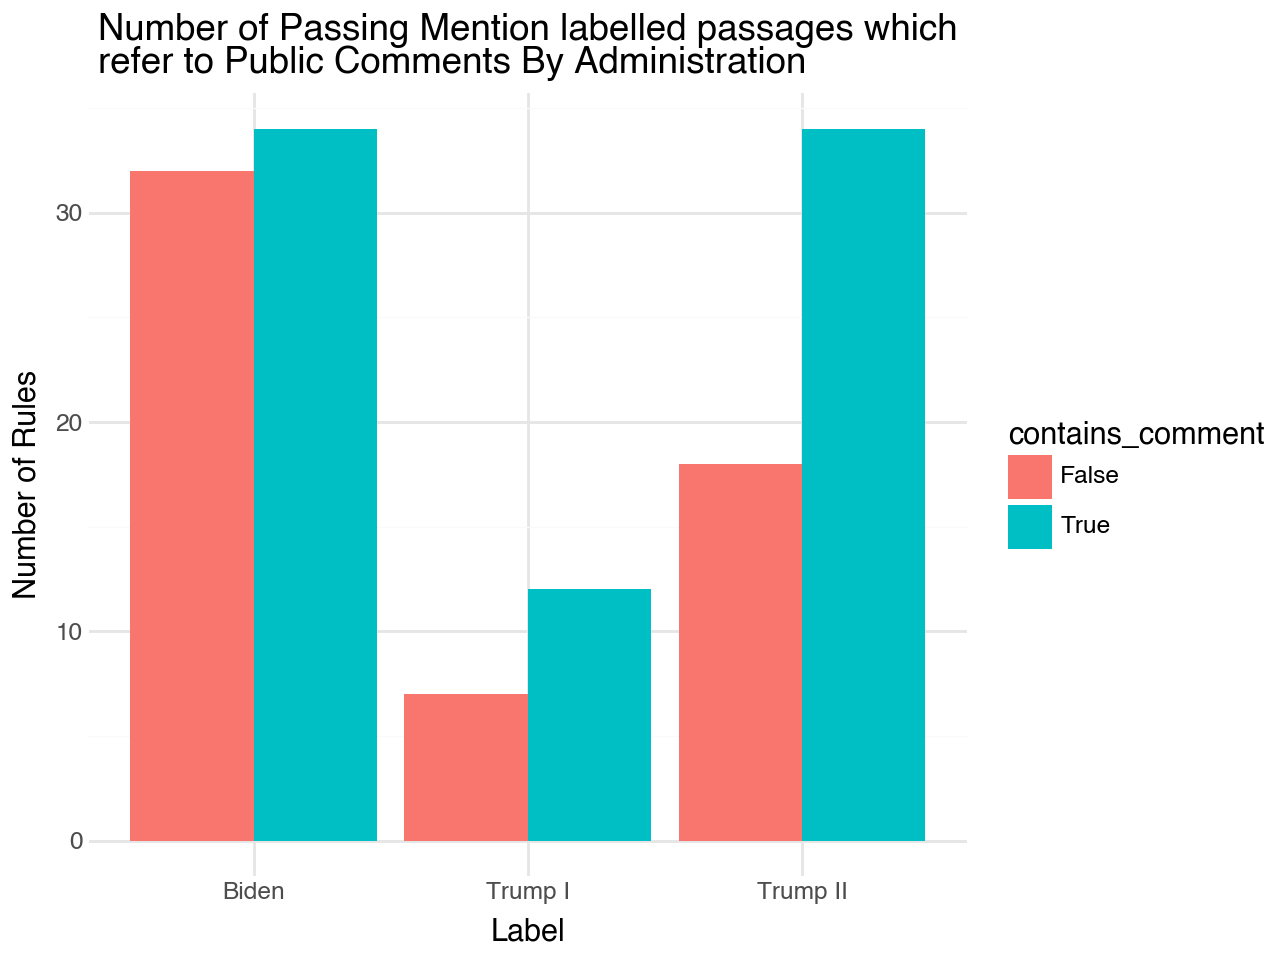

In [22]:
df_passing_mention = df_rules[df_rules["gemini_label"] == "passing mention"]
plot2 = (plotnine.ggplot(df_passing_mention, plotnine.aes(x='administration', fill='contains_comment'))
               + plotnine.geom_bar(position='dodge')
               + plotnine.labs(title='Number of Passing Mention labelled passages which\nrefer to Public Comments By Administration',
                        x='Label',
                        y='Number of Rules')
                + plotnine.theme(axis_text_x=plotnine.element_text(rotation=45, hjust=1))
                + plotnine.theme_minimal())
plot2


In [24]:
df_label_matched = df_passing_mention.copy()
df_label_matched[ 'matched_artificial_intelligence' ] = df_label_matched[ 'matched_terms' ].str.contains('artificial intelligence', case=False, na=False)
df_label_matched[ 'matched_machine_learning' ] = df_label_matched[ 'matched_terms' ].str.contains('machine learning', case=False, na=False)

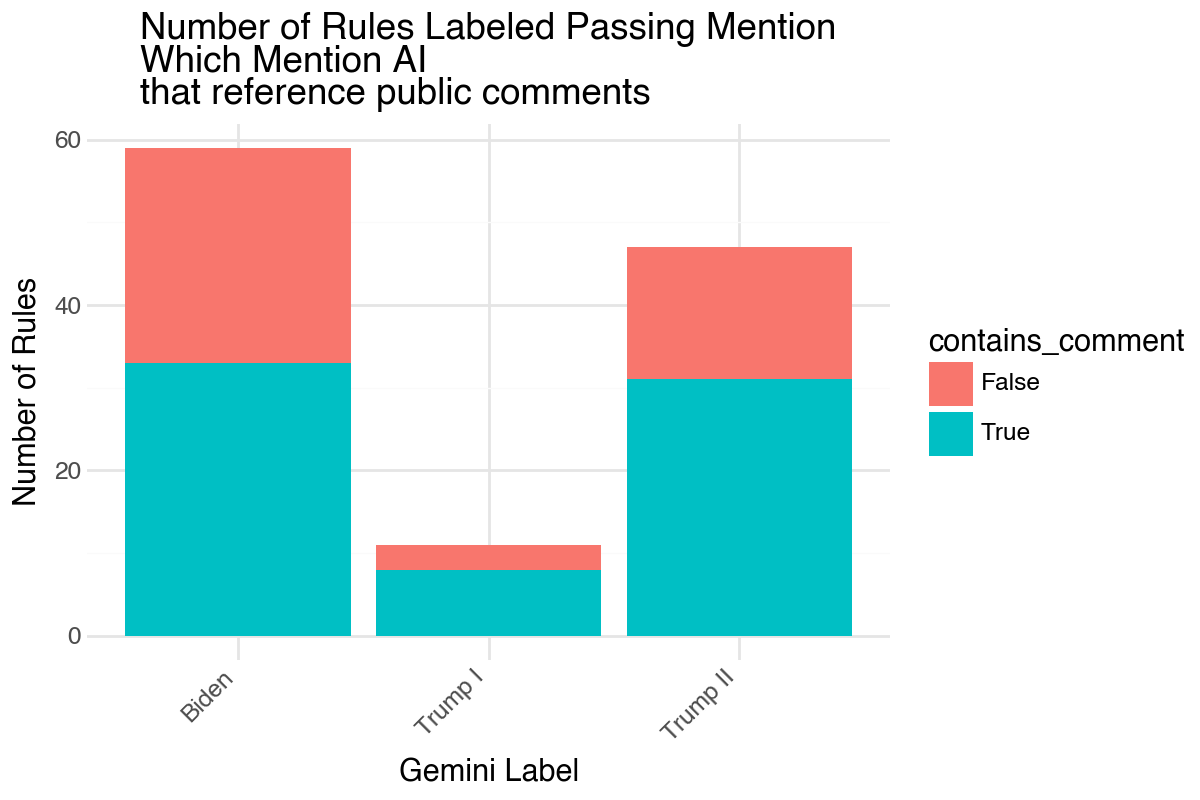

In [37]:
df_ai_true = df_label_matched[df_label_matched['matched_artificial_intelligence'] == True]
plot3a = (plotnine.ggplot(df_ai_true, plotnine.aes(x='administration',fill='contains_comment'))
               + plotnine.geom_bar()  # Single clean color instead of a legend
               + plotnine.labs(title='Number of Rules Labeled Passing Mention\nWhich Mention AI\nthat reference public comments', x='Gemini Label', y='Number of Rules')
                + plotnine.theme_minimal()
                + plotnine.theme(axis_text_x=plotnine.element_text(rotation=45, hjust=1), figure_size=(6, 4))
)
plot3a


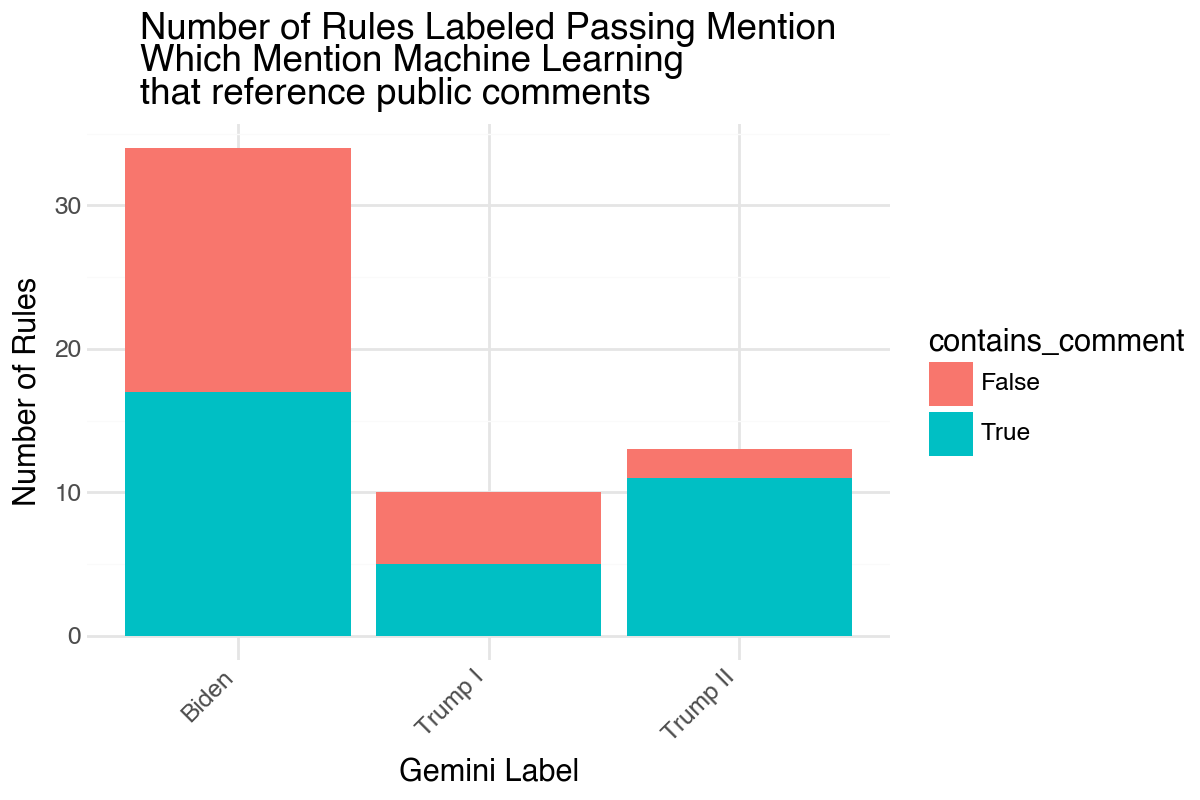

In [35]:
df_ml_true = df_label_matched[df_label_matched['matched_machine_learning'] == True]
plot3a = (plotnine.ggplot(df_ml_true, plotnine.aes(x='administration',fill='contains_comment'))
               + plotnine.geom_bar()  # Single clean color instead of a legend
               + plotnine.labs(title='Number of Rules Labeled Passing Mention\nWhich Mention Machine Learning\nthat reference public comments', x='Gemini Label', y='Number of Rules')
                + plotnine.theme_minimal()
                + plotnine.theme(axis_text_x=plotnine.element_text(rotation=45, hjust=1), figure_size=(6, 4))
)
plot3a
